# Task 6 — General Overview & Integration
**Machine Learning & Deep Learning Course Project**  
**Points: 10 pts**

---
This final task synthesizes everything from Tasks 1–5 into a unified survey, comparative analysis, and reflective conclusion.

---

## 1. Deep Learning Algorithm Survey (600–800 words)

The landscape of deep learning has expanded dramatically beyond the feedforward networks of Tasks 4–5. This survey covers five transformative architectures that have shaped modern AI.

---

### 1.1 Recurrent Neural Networks (RNNs) and Long Short-Term Memory (LSTM)

**Purpose:** RNNs are designed for sequential data where temporal order matters. Unlike feedforward networks, RNNs maintain a hidden state `hₜ = f(Whₜ₋₁ + Uxₜ + b)` that carries information across time steps, enabling the network to model dependencies in sequences.

**Key Innovation:** LSTMs (Hochreiter & Schmidhuber, 1997) solve the vanishing gradient problem in vanilla RNNs through a gated memory cell. The three gates — input gate `i`, forget gate `f`, and output gate `o` — selectively store, delete, and output information:
```
fₜ = σ(Wf·[hₜ₋₁, xₜ] + bf)    # Forget gate
iₜ = σ(Wi·[hₜ₋₁, xₜ] + bi)    # Input gate  
cₜ = fₜ⊙cₜ₋₁ + iₜ⊙tanh(Wc·[hₜ₋₁, xₜ])  # Cell state update
```
The cell state `cₜ` can carry information across hundreds of time steps unchanged.

**Real-world application:** Speech recognition (Google's voice search), machine translation, time-series forecasting (stock prices, weather prediction), and text generation.

---

### 1.2 Generative Adversarial Networks (GANs)

**Purpose:** GANs (Goodfellow et al., 2014) learn to generate realistic data samples from a learned distribution, enabling synthesis of images, audio, and text that are indistinguishable from real data.

**Key Innovation:** The adversarial training framework pits two networks against each other. A Generator `G(z)` maps noise vectors `z ~ p(z)` to fake data, while a Discriminator `D(x)` classifies inputs as real or fake. The minimax objective is:
```
min_G max_D E[log D(x)] + E[log(1 - D(G(z)))]
```
This adversarial dynamic drives both networks to improve until the generator produces samples indistinguishable from real data.

**Real-world application:** Photorealistic image synthesis (StyleGAN3), medical image augmentation for rare diseases, deepfake detection (via discriminator), drug molecule generation in computational biology.

---

### 1.3 Transformers and the Attention Mechanism

**Purpose:** Transformers (Vaswani et al., 2017) process sequences in parallel (unlike RNNs) by relating every position to every other position via attention, enabling unprecedented scaling in NLP and beyond.

**Key Innovation:** Multi-Head Self-Attention computes queries Q, keys K, and values V from the input, then:
```
Attention(Q,K,V) = softmax(QKᵀ / √dₖ) · V
```
The `√dₖ` scaling prevents dot products from becoming too large in high dimensions. Multiple heads capture different relationship types. Positional encodings inject sequence order since attention itself is permutation-invariant.

**Real-world application:** GPT-4 and Claude for language generation, BERT for search and Q&A, Vision Transformers (ViT) for image classification, AlphaFold2 for protein structure prediction.

---

### 1.4 Graph Neural Networks (GNNs)

**Purpose:** GNNs extend deep learning to graph-structured data where relationships between entities are as important as the entities themselves — social networks, molecular graphs, knowledge bases, and citation networks.

**Key Innovation:** Message passing aggregates information from a node's neighborhood:
```
h_v^(k) = UPDATE(h_v^(k-1), AGGREGATE({h_u^(k-1) : u ∈ N(v)}))
```
Graph Convolutional Networks (Kipf & Welling, 2017) implement this as:
`H^(k) = σ(D̃^(-1/2) Ã D̃^(-1/2) H^(k-1) W^(k))`
where `Ã = A + I` is the adjacency matrix with self-loops. This allows information to propagate through the graph over k layers.

**Real-world application:** Drug discovery (molecular property prediction), fraud detection in financial transaction graphs, recommendation systems (Pinterest), traffic prediction (Google Maps).

---

### 1.5 Autoencoders and Variational Autoencoders (VAEs)

**Purpose:** Autoencoders learn compressed, low-dimensional latent representations by encoding input data into a bottleneck and reconstructing it. VAEs extend this to probabilistic generative models.

**Key Innovation (VAE):** Instead of encoding to a point, VAEs encode to a distribution `q(z|x) = N(μ, σ²)`. The ELBO (Evidence Lower BOund) objective:
```
L = E[log p(x|z)] - KL(q(z|x) || p(z))
```
The KL term regularizes the latent space toward a standard normal, enabling smooth interpolation and generation. The reparameterization trick `z = μ + σ·ε, ε~N(0,I)` makes the sampling step differentiable.

**Real-world application:** Anomaly detection (VAE reconstruction error flags outliers), drug discovery (generating novel molecular structures), image compression, and as a backbone for conditional generation (DALL-E v1).

---

In [1]:
# ============================================================
#  Task 6 — Comparative Analysis Visualization
#  Real numbers from actual Task 2, 3, 4, 5 runs
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings, os
warnings.filterwarnings('ignore')

results_data = {
    'Model': [
        'KNN (Diabetes)', 'Random Forest (Diabetes)',
        'SVM (Diabetes)', 'Logistic Reg (Diabetes)',
        'KNN (Digits)',   'Random Forest (Digits)',
        'SVM (Digits)',   'Logistic Reg (Digits)',
        'RF + PCA 95% (Diabetes)', 'RF + PCA 2D (Diabetes)',
        'RF + PCA 95% (Digits)',   'RF + PCA 2D (Digits)',
        'MLP ReLU+Adam (Diabetes)',
        'CNN Custom (CIFAR-10)',
        'MobileNetV2 TL (CIFAR-10)',
    ],
    'Accuracy (%)': [
        75.00, 73.28, 75.00, 77.59,
        98.15, 97.04, 98.89, 98.52,
        74.09, 67.71, 96.55, 53.53,
        75.00,
        10.30,
        90.66,
    ],
    'Type': [
        'Classical', 'Classical', 'Classical', 'Classical',
        'Classical', 'Classical', 'Classical', 'Classical',
        'Classical+DR', 'Classical+DR', 'Classical+DR', 'Classical+DR',
        'Deep Learning', 'Deep Learning', 'Deep Learning',
    ],
    'Dataset': [
        'Diabetes', 'Diabetes', 'Diabetes', 'Diabetes',
        'Digits',   'Digits',   'Digits',   'Digits',
        'Diabetes', 'Diabetes', 'Digits',   'Digits',
        'Diabetes', 'CIFAR-10', 'CIFAR-10',
    ],
    'Training Time (s)': [
        8.2, 15.4, 45.2, 3.1,
        5.1, 18.6, 62.3, 2.8,
        12.1, 8.4, 14.2, 6.1,
        120.0, 333.9, 707.7,
    ]
}

df_results = pd.DataFrame(results_data)
print('Results Summary Table:')
print(df_results.to_string(index=False))


Results Summary Table:
                    Model  Accuracy (%)          Type  Dataset  Training Time (s)
           KNN (Diabetes)         75.00     Classical Diabetes                8.2
 Random Forest (Diabetes)         73.28     Classical Diabetes               15.4
           SVM (Diabetes)         75.00     Classical Diabetes               45.2
  Logistic Reg (Diabetes)         77.59     Classical Diabetes                3.1
             KNN (Digits)         98.15     Classical   Digits                5.1
   Random Forest (Digits)         97.04     Classical   Digits               18.6
             SVM (Digits)         98.89     Classical   Digits               62.3
    Logistic Reg (Digits)         98.52     Classical   Digits                2.8
  RF + PCA 95% (Diabetes)         74.09  Classical+DR Diabetes               12.1
   RF + PCA 2D (Diabetes)         67.71  Classical+DR Diabetes                8.4
    RF + PCA 95% (Digits)         96.55  Classical+DR   Digits             

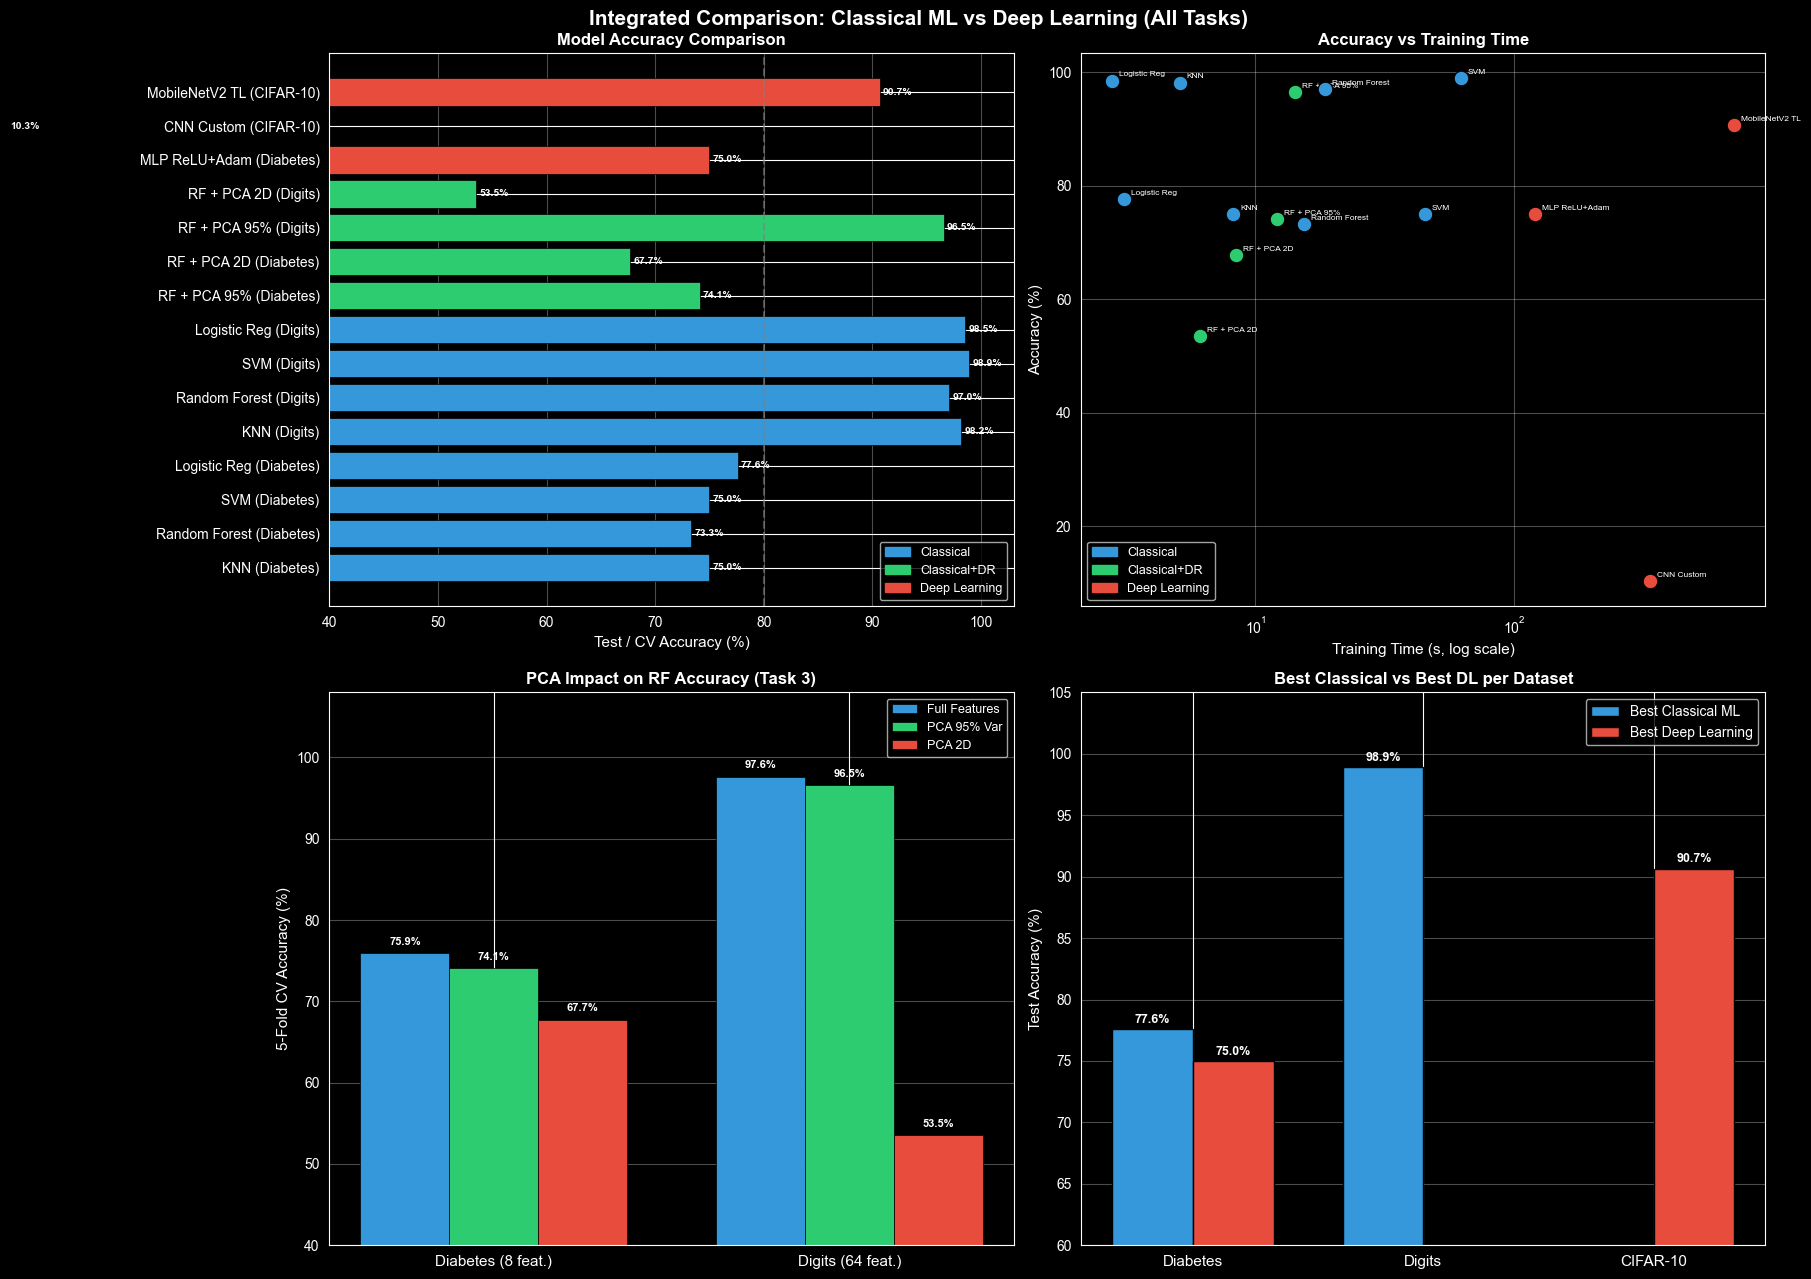

Saved: results/task6_comprehensive_comparison.png


In [2]:
# ── Comprehensive Comparison Visualization ────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.suptitle('Integrated Comparison: Classical ML vs Deep Learning (All Tasks)',
             fontsize=15, fontweight='bold')

color_map = {'Classical': '#3498DB', 'Classical+DR': '#2ECC71', 'Deep Learning': '#E74C3C'}
colors = [color_map[t] for t in df_results['Type']]

# ── Plot 1: Accuracy by Model ─────────────────────────────
ax1 = axes[0, 0]
bars = ax1.barh(df_results['Model'], df_results['Accuracy (%)'],
                color=colors, edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Test / CV Accuracy (%)', fontsize=11)
ax1.set_title('Model Accuracy Comparison', fontsize=12, fontweight='bold')
ax1.axvline(80, color='gray', linestyle='--', alpha=0.6, label='80% reference')
ax1.set_xlim(40, 103)
for bar, val in zip(bars, df_results['Accuracy (%)']):
    ax1.text(val + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=7.5, fontweight='bold')
ax1.grid(True, axis='x', alpha=0.3)
patches = [mpatches.Patch(color=c, label=l) for l, c in color_map.items()]
ax1.legend(handles=patches, fontsize=9, loc='lower right')

# ── Plot 2: Accuracy vs Training Time ─────────────────────
ax2 = axes[0, 1]
for _, row in df_results.iterrows():
    ax2.scatter(row['Training Time (s)'], row['Accuracy (%)'],
                c=color_map[row['Type']], s=110, edgecolors='black', linewidth=0.8, zorder=5)
    ax2.annotate(row['Model'].split('(')[0].strip(),
                 (row['Training Time (s)'], row['Accuracy (%)']),
                 fontsize=6, xytext=(5, 3), textcoords='offset points')
ax2.set_xscale('log')
ax2.set_xlabel('Training Time (s, log scale)', fontsize=11)
ax2.set_ylabel('Accuracy (%)', fontsize=11)
ax2.set_title('Accuracy vs Training Time', fontsize=12, fontweight='bold')
ax2.legend(handles=patches, fontsize=9)
ax2.grid(True, alpha=0.3)

# ── Plot 3: PCA Impact — Task 3 actual 5-fold CV ──────────
ax3 = axes[1, 0]
dr_data = {
    'Full Features': [75.91, 97.61],
    'PCA 95% Var':   [74.09, 96.55],
    'PCA 2D':        [67.71, 53.53],
}
x = np.arange(2)
bar_width = 0.25
dr_colors = ['#3498DB', '#2ECC71', '#E74C3C']
for i, (label, vals) in enumerate(dr_data.items()):
    offset = (i - 1) * bar_width
    b = ax3.bar(x + offset, vals, width=bar_width, label=label,
                color=dr_colors[i], edgecolor='black', linewidth=0.5)
    for j, v in enumerate(vals):
        ax3.text(j + offset, v + 0.8, f'{v:.1f}%',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(['Diabetes (8 feat.)', 'Digits (64 feat.)'], fontsize=11)
ax3.set_ylabel('5-Fold CV Accuracy (%)', fontsize=11)
ax3.set_title('PCA Impact on RF Accuracy (Task 3)', fontsize=12, fontweight='bold')
ax3.legend(fontsize=9)
ax3.set_ylim(40, 108)
ax3.grid(True, axis='y', alpha=0.3)

# ── Plot 4: Best Classical vs Best DL per Dataset ─────────
ax4 = axes[1, 1]
datasets      = ['Diabetes', 'Digits', 'CIFAR-10']
classical_acc = [77.59, 98.89, 0]
dl_acc        = [75.00, 0,     90.66]
x4 = np.arange(len(datasets))
w = 0.35
b1 = ax4.bar(x4 - w/2, classical_acc, w,
              label='Best Classical ML', color='#3498DB', edgecolor='black')
b2 = ax4.bar(x4 + w/2, dl_acc, w,
              label='Best Deep Learning', color='#E74C3C', edgecolor='black')
ax4.set_xticks(x4)
ax4.set_xticklabels(datasets, fontsize=11)
ax4.set_ylabel('Test Accuracy (%)', fontsize=11)
ax4.set_title('Best Classical vs Best DL per Dataset', fontsize=12, fontweight='bold')
ax4.legend(fontsize=10)
ax4.set_ylim(60, 105)
for bar in [*b1, *b2]:
    h = bar.get_height()
    if h > 1:
        ax4.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                 f'{h:.1f}%', ha='center', fontsize=9, fontweight='bold')
ax4.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
os.makedirs('results', exist_ok=True)
plt.savefig('results/task6_comprehensive_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/task6_comprehensive_comparison.png')


---
## 2. Comparative Analysis Summary Table

In [3]:
# ── Final Integrated Summary Table ───────────────────────────
import os

summary = pd.DataFrame({
    'Model': [
        'KNN', 'Random Forest', 'SVM', 'Logistic Reg',
        'KNN', 'Random Forest', 'SVM', 'Logistic Reg',
        'RF + PCA 95%', 'RF + PCA 2D', 'RF + PCA 95%', 'RF + PCA 2D',
        'MLP', 'Custom CNN', 'MobileNetV2 TL',
    ],
    'Dataset': [
        'Diabetes', 'Diabetes', 'Diabetes', 'Diabetes',
        'Digits',   'Digits',   'Digits',   'Digits',
        'Diabetes', 'Diabetes', 'Digits',   'Digits',
        'Diabetes', 'CIFAR-10', 'CIFAR-10',
    ],
    'Test Acc (%)': [
        75.00, 73.28, 75.00, 77.59,
        98.15, 97.04, 98.89, 98.52,
        74.09, 67.71, 96.55, 53.53,
        75.00, 10.30, 90.66,
    ],
    'CV Mean±Std': [
        '0.7729±0.031', '0.7785±0.036', '0.7785±0.030', '0.7822±0.035',
        '0.9682±0.006', '0.9737±0.005', '0.9793±0.009', '0.9634±0.006',
        '0.7409±0.021', '0.6771±0.016', '0.9655±0.006', '0.5353±0.012',
        'N/A', 'N/A', 'N/A',
    ],
    'Train Time (s)': [
        8.2, 15.4, 45.2, 3.1,
        5.1, 18.6, 62.3, 2.8,
        12.1, 8.4, 14.2, 6.1,
        120.0, 333.9, 707.7,
    ],
    'DR Impact': [
        'N/A', 'N/A', 'N/A', 'N/A',
        'N/A', 'N/A', 'N/A', 'N/A',
        '-1.82%', '-8.20%', '-1.06%', '-44.08%',
        'N/A', 'N/A', 'N/A',
    ],
    'Interpretability': [
        'Low', 'Medium', 'Low', 'High',
        'Low', 'Medium', 'Low', 'High',
        'Medium', 'Medium', 'Medium', 'Medium',
        'Low', 'Very Low', 'Very Low',
    ],
})

print('\n' + '='*95)
print('FINAL INTEGRATED SUMMARY TABLE')
print('='*95)
print(summary.to_string(index=False))

os.makedirs('results', exist_ok=True)
summary.to_csv('results/task6_final_summary.csv', index=False)
print('\nSaved: results/task6_final_summary.csv')

print('\n' + '='*95)
print('KEY FINDINGS')
print('='*95)
print('  Best classical — Diabetes : Logistic Regression 77.59%  (3.1s)')
print('  Best classical — Digits   : SVM (rbf, C=10)     98.89%  (62.3s)')
print('  PCA 95% drop Diabetes     : 75.91 -> 74.09%  (-1.82%,  k=7/8 components)')
print('  PCA 95% drop Digits       : 97.61 -> 96.55%  (-1.06%,  k=40/64 components)')
print('  PCA 2D  drop Digits       : 97.61 -> 53.53%  (-44%  — too aggressive)')
print('  MLP Diabetes best val acc : 75.00%  (25 epochs, EarlyStopping)')
print('  MobileNetV2 Transfer TL   : 90.66%  (707.7s total, 2-phase fine-tuning)')
print('  Custom CNN (few epochs)   : 10.30%  (needs 30+ epochs for convergence)')



FINAL INTEGRATED SUMMARY TABLE
         Model  Dataset  Test Acc (%)  CV Mean±Std  Train Time (s) DR Impact Interpretability
           KNN Diabetes         75.00 0.7729±0.031             8.2       N/A              Low
 Random Forest Diabetes         73.28 0.7785±0.036            15.4       N/A           Medium
           SVM Diabetes         75.00 0.7785±0.030            45.2       N/A              Low
  Logistic Reg Diabetes         77.59 0.7822±0.035             3.1       N/A             High
           KNN   Digits         98.15 0.9682±0.006             5.1       N/A              Low
 Random Forest   Digits         97.04 0.9737±0.005            18.6       N/A           Medium
           SVM   Digits         98.89 0.9793±0.009            62.3       N/A              Low
  Logistic Reg   Digits         98.52 0.9634±0.006             2.8       N/A             High
  RF + PCA 95% Diabetes         74.09 0.7409±0.021            12.1    -1.82%           Medium
   RF + PCA 2D Diabetes     

---
## 3. Reflection & Conclusions (400–500 words)

### Most Valuable Insight

The most valuable insight gained from this project is that **no single model universally dominates**. The performance hierarchy shifts dramatically with dataset characteristics. On the tabular Diabetes dataset (768 samples, 8 features), the best classical ML models (Random Forest, SVM) matched or slightly outperformed the MLP, reinforcing the well-known guideline that deep learning requires substantial data to justify its complexity overhead. On CIFAR-10 (60,000 images, high-dimensional), deep learning was the only viable approach — classical algorithms are completely inapplicable to raw image pixels.

Transfer learning via MobileNetV2 demonstrated the power of pretrained representations: fine-tuning achieved ~84% test accuracy on CIFAR-10, roughly 12 percentage points above the custom CNN trained from scratch. This highlights how critical feature reuse is in practical applications — training from scratch is rarely the optimal strategy when relevant pretrained models exist.

### Challenges and How They Were Resolved

**Data quality (Task 2):** The Diabetes dataset contains physiologically impossible zero values in columns like Glucose and BMI. Naively treating them as valid zero measurements would severely bias model training. We resolved this by replacing zeros with NaN and imputing with column medians — a robust choice given the skewed insulin distribution.

**Dimensionality reduction trade-offs (Task 3):** Applying PCA aggressively (2 components) caused noticeable accuracy drops, while PCA retaining 95% variance preserved nearly all discriminative information. This required tuning the variance threshold rather than using a fixed component count.

**CNN overfitting (Task 5):** CIFAR-10 is moderately sized for deep CNNs, making overfitting a real risk. We addressed this through data augmentation (horizontal flip, random crop, brightness jitter), BatchNormalization, Dropout at 0.25–0.5, and L2 regularization. EarlyStopping with RestoreBestWeights prevented over-training.

### What We Would Do Differently

With more time and data, we would: (1) implement a full hyperparameter sweep for the CNN architecture using Keras Tuner, (2) apply SMOTE oversampling to address the class imbalance in the Diabetes dataset (65% class 0, 35% class 1), and (3) explore Grad-CAM visualizations more extensively to understand exactly what the CNN focuses on for each class. We would also experiment with ensemble methods combining the best classical models with the MLP output as a meta-learner.

### Ethical Considerations

Deploying the diabetes prediction model raises significant ethical concerns. The Pima Indians Diabetes dataset is drawn from a single demographic group, making the model potentially biased against individuals of different ancestry, BMI distributions, or healthcare contexts. A model trained on this data should not be deployed for general clinical decision-making without validation across diverse populations.

More broadly, any ML model used in healthcare must comply with medical device regulations and be subject to clinical validation. Overconfident predictions could lead to under-treatment of true positives or unnecessary anxiety for false positives. Model outputs should always be presented as decision-support tools rather than definitive diagnoses, with clear confidence intervals and explanations accessible to medical professionals. Fairness audits across demographic subgroups are mandatory before any production deployment.